### Visualizações dos dados do Benchmark Dataset (Tsinghua Lab) para o participante S1

In [22]:
import mne
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

plt.rcParams['figure.figsize'] = [16., 5.]

# Lê 64 canais do arquivo '64-channels.loc'
channels = pd.read_csv('data/input/64-channels.loc', sep=r'\s+', header=None, usecols=[3])[3].tolist()

# Objetos Epochs salvos no pré-processamento
epochs_unfiltered = mne.read_epochs('data/output/S1_epo.fif', preload=True, verbose=False)
epochs_filtered = mne.read_epochs('data/output/S1_filtered_epo.fif', preload=True, verbose=False)

**Espectro médio (com e sem filtro)**

Para conferir o efeito do filtro passa-faixa, realizado no pré-processamento, foi calculado a *Power Spectral Density* (PSD), que mostra quanta energia do sinal existe em cada frequência. O cálculo foi feito em cada epoch através do método *multitaper* do MNE, de 1 a 60Hz (apenas para incluir até 50Hz no gráfico), e depois foi retirada a média de cada epoch e de todos os canais; resultando em uma única curva para cada objeto.

Como o MNE retorna a potência em V²/Hz, o valor foi multiplicado por 10¹² para passar para µV²/Hz, que é a unidade de sinal que o dataset utiliza. Aleḿ disso, visto que, em escala linear, só as frequências baixas ficam evidentes, a potência foi convertida para decibéis.

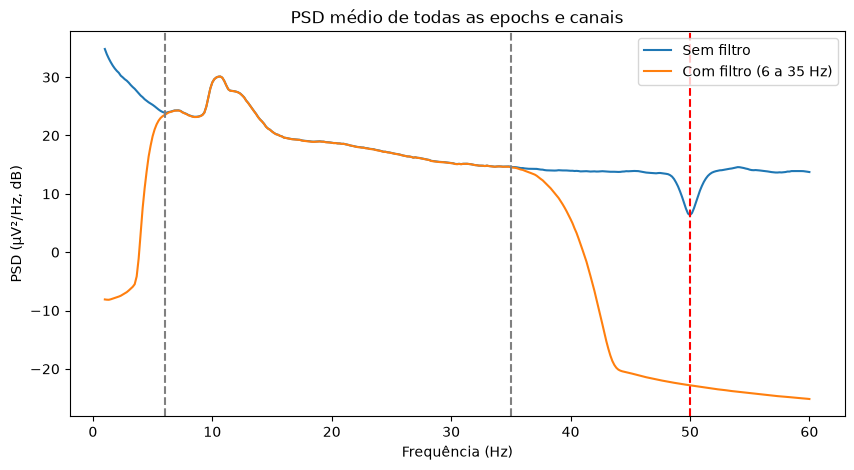

In [23]:
def mean_psd_db(epochs, fmin=1, fmax=60):
    psd = epochs.compute_psd(method='multitaper', fmin=fmin, fmax=fmax, verbose=False)
    mean_psd = psd.get_data().mean(axis=(0, 1))
    return psd.freqs, 10 * np.log10(mean_psd * 1e12)

freq_axis, psd_unfiltered = mean_psd_db(epochs_unfiltered)
_, psd_filtered = mean_psd_db(epochs_filtered)

plt.figure(figsize=(10, 5))
plt.plot(freq_axis, psd_unfiltered, label='Sem filtro')
plt.plot(freq_axis, psd_filtered, label='Com filtro (6 a 35 Hz)')
plt.axvline(x=6, linestyle='--', color='gray')
plt.axvline(x=35, linestyle='--', color='gray')
plt.axvline(x=50, linestyle='--', color='red')
plt.title('PSD médio de todas as epochs e canais')
plt.xlabel('Frequência (Hz)')
plt.ylabel('PSD (µV²/Hz, dB)')
plt.legend()
plt.show()

No gráfico, foram marcadas as bordas da faixa do filtro, em 6 e 35Hz, e a frequência de 50Hz, para observar se o sinal sem filtro ainda tem algum efeito da rede elétrica do laboratório.

Podemos observar que as curvas do PSD com e sem filtro coincidem entre 6 e 35Hz e se separam fora dessa faixa, e a queda em 50Hz no sinal indica que o filtro notch aplicado já havia removido o ruído da rede elétrica.

**Sinal de uma epoch**

A função `print_graphs` apresenta uma epoch no domínio frequência, além do espectrograma. Para isso, recebe um objeto `Epochs`, o índice da epoch e uma identificação da versão do sinal, utilizando a frequência de amostragem do próprio objeto.  A epoch utilizada é a primeira, correspondente ao bloco 0 e ao alvo 0.

No gráfico do PSD, é mostrado o PSD de cada um dos canais, já o espectrograma é calculado a partir da média dos canais, já que não é possível sobrepor canais por ser uma imagem, permitindo representar a variação da frequência ao longo do tempo. 

In [24]:
# Canais da região occipital e parieto-occipital, onde a resposta visual é mais forte
unfiltered = epochs_unfiltered.copy().pick(channels)
filtered = epochs_filtered.copy().pick(channels)

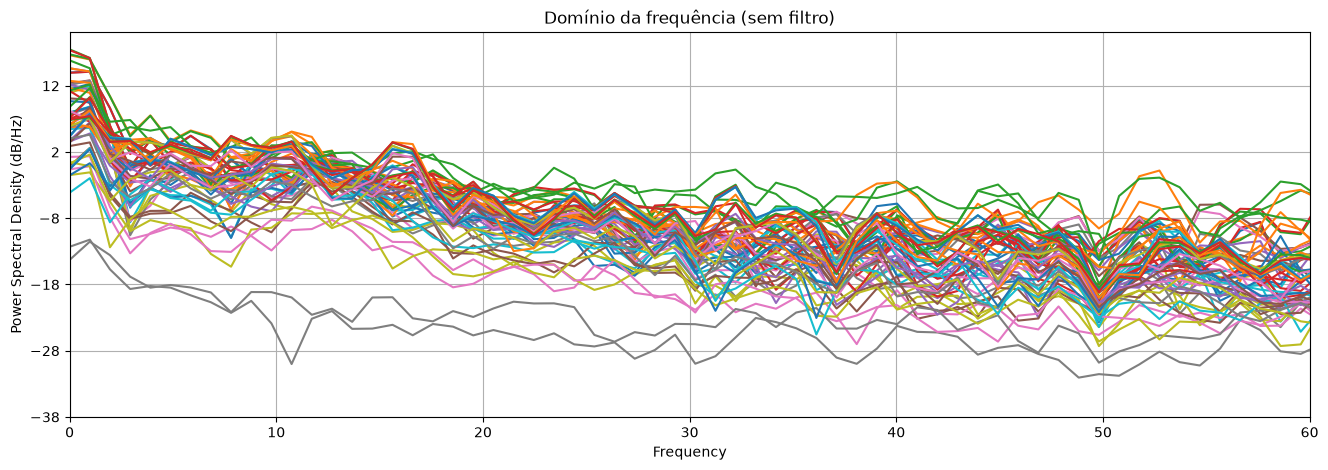

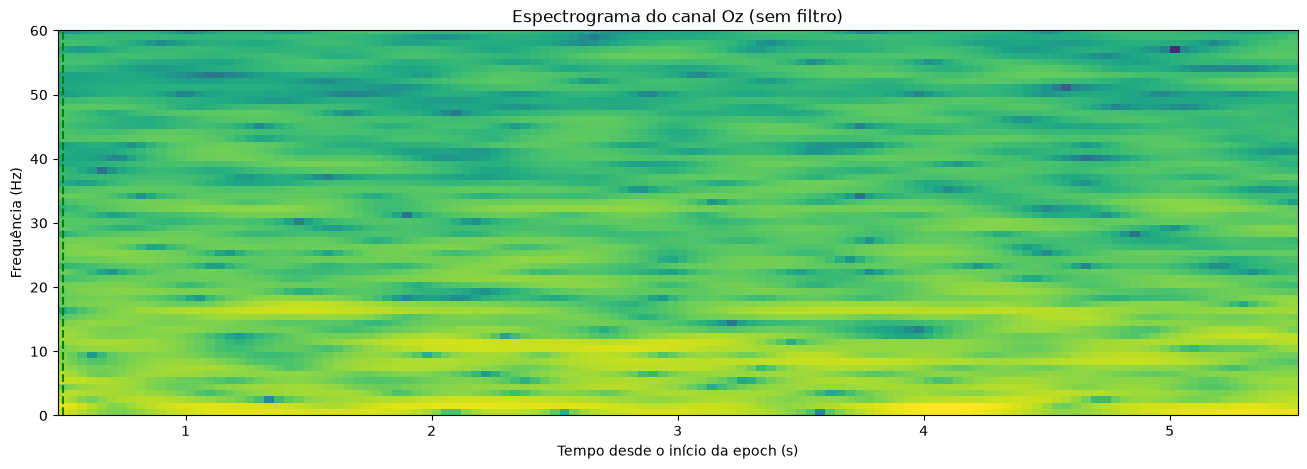

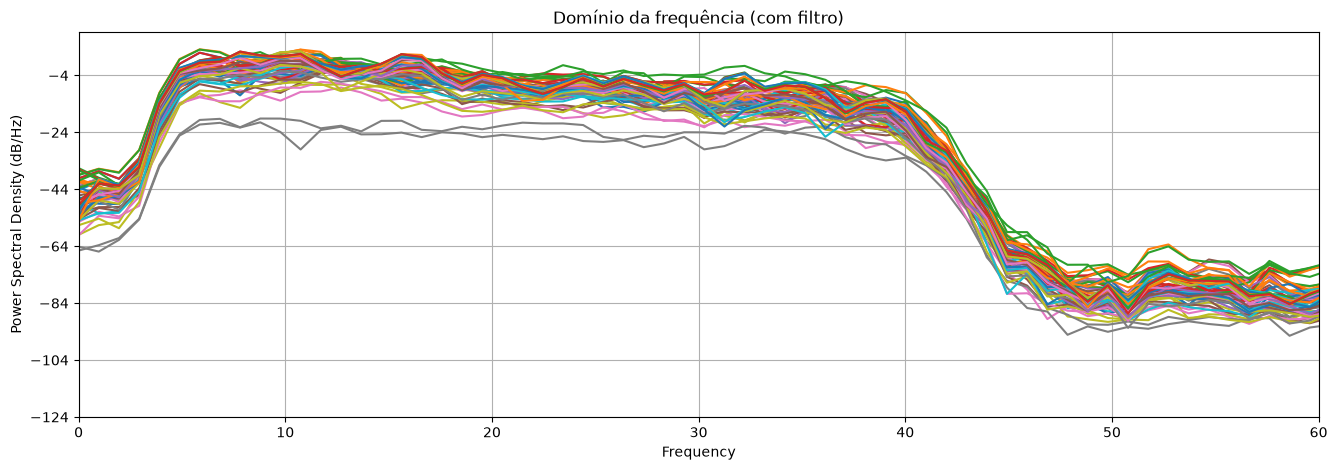

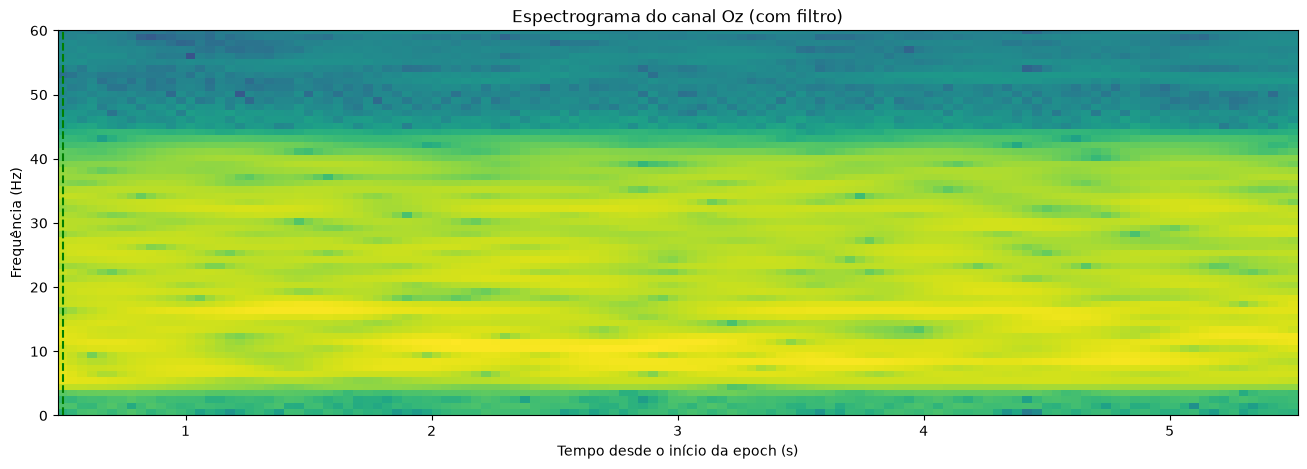

In [25]:
# Mostra o sinal no PSD e o espectrograma de uma epoch
def print_graphs(epochs, index, label):
    data = epochs[index].get_data()[0] * 1e6
    times = epochs.times
    fs = epochs.info['sfreq']

    for i in range(len(epochs.ch_names)):
        plt.psd(data[i, :], Fs=fs, label=epochs.ch_names[i])
    plt.title('Domínio da frequência (' + label + ')')
    plt.xlim(0, 60)
    plt.show()

    oz = epochs.ch_names.index('Oz')
    plt.specgram(data[oz], Fs=fs, NFFT=250, noverlap=240)
    plt.axvline(x=-times[0], linestyle='--', color='green')
    plt.title('Espectrograma do canal Oz (' + label + ')')
    plt.xlabel('Tempo desde o início da epoch (s)')
    plt.ylabel('Frequência (Hz)')
    plt.ylim(0, 60)
    plt.show()

print_graphs(unfiltered, 0, 'sem filtro')
print_graphs(filtered, 0, 'com filtro')

No PSD da epoch 0 sem filtro, a potência é maior perto de 0 Hz e cai com a frequência, e não aparece pico na frequência do alvo porque os 64 canais estão misturados em uma única epoch. E no espectrograma do Oz sem filtro, as faixas se mantêm estáveis durante toda a epoch, sem mudança clara quando o estímulo começa. 

Já no PSD da epoch 0 com filtro, forma-se um patamar entre em torno de 5 e 40 Hz e a energia despenca depois, o que confirma o efeito do passa-faixa em todos os canais. Enquanto no espectrograma do Oz com filtro, a energia também fica predominante entre 5 e 40 Hz.